# Cross-validation and business-cost analysis

This notebook summarizes five-fold stratified cross-validation for every configured model. We compare mean performance, fold-to-fold variability, aggregated confusion matrices, and a maintenance-oriented error cost.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'reports').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

results = pd.read_csv(PROJECT_ROOT / 'reports' / 'cross_validation_results.csv')
confusion_payload = json.loads((PROJECT_ROOT / 'reports' / 'cross_validation_confusion_matrices.json').read_text())
labels = confusion_payload['labels']
confusion_matrices = confusion_payload['matrices']
display(results.round(4))

,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,repair_recall_mean,repair_recall_std,business_cost_mean,business_cost_std
0,rf_balanced_100,0.8002,0.0060,0.7010,0.0052,0.4503,0.0263,0.3596,0.0070
1,rf_balanced_leaf2,0.7895,0.0061,0.7008,0.0039,0.5610,0.0279,0.3381,0.0045
2,rf_balanced_depth20,0.7871,0.0074,0.6967,0.0056,0.5564,0.0195,0.3419,0.0047
3,extra_trees_balanced_leaf2,0.7835,0.0064,0.6944,0.0034,0.5733,0.0224,0.3405,0.0030
4,extra_trees_balanced_100,0.8029,0.0050,0.6870,0.0033,0.3426,0.0153,0.3882,0.0038
5,extra_trees_balanced_features70,0.7993,0.0043,0.6826,0.0023,0.3375,0.0203,0.3933,0.0040
6,lgbm_balanced_leaves63,0.7488,0.0087,0.6658,0.0080,0.6294,0.0127,0.3589,0.0096
7,xgb_depth8,0.7955,0.0029,0.6539,0.0069,0.2240,0.0182,0.4301,0.0066
8,hist_gradient_boosting_regularized,0.7901,0.0042,0.6532,0.0079,0.2360,0.0208,0.4320,0.0082
9,hist_gradient_boosting_lr005,0.7873,0.0039,0.6510,0.0089,0.2365,0.0202,0.4347,0.0088


In [2]:
metric_columns = [
    'model', 'accuracy_mean', 'accuracy_std', 'macro_f1_mean', 'macro_f1_std',
    'repair_recall_mean', 'repair_recall_std', 'business_cost_mean', 'business_cost_std'
]
display(results[metric_columns].sort_values('business_cost_mean').round(4))

,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,repair_recall_mean,repair_recall_std,business_cost_mean,business_cost_std
1,rf_balanced_leaf2,0.7895,0.0061,0.7008,0.0039,0.5610,0.0279,0.3381,0.0045
3,extra_trees_balanced_leaf2,0.7835,0.0064,0.6944,0.0034,0.5733,0.0224,0.3405,0.0030
2,rf_balanced_depth20,0.7871,0.0074,0.6967,0.0056,0.5564,0.0195,0.3419,0.0047
6,lgbm_balanced_leaves63,0.7488,0.0087,0.6658,0.0080,0.6294,0.0127,0.3589,0.0096
0,rf_balanced_100,0.8002,0.0060,0.7010,0.0052,0.4503,0.0263,0.3596,0.0070
11,lgbm_balanced_leaves31,0.7193,0.0075,0.6424,0.0065,0.6877,0.0248,0.3715,0.0096
12,catboost_balanced_depth8,0.6959,0.0085,0.6219,0.0085,0.7132,0.0163,0.3875,0.0120
4,extra_trees_balanced_100,0.8029,0.0050,0.6870,0.0033,0.3426,0.0153,0.3882,0.0038
5,extra_trees_balanced_features70,0.7993,0.0043,0.6826,0.0023,0.3375,0.0203,0.3933,0.0040
13,catboost_balanced_depth6,0.6793,0.0099,0.6073,0.0098,0.7130,0.0194,0.4041,0.0144


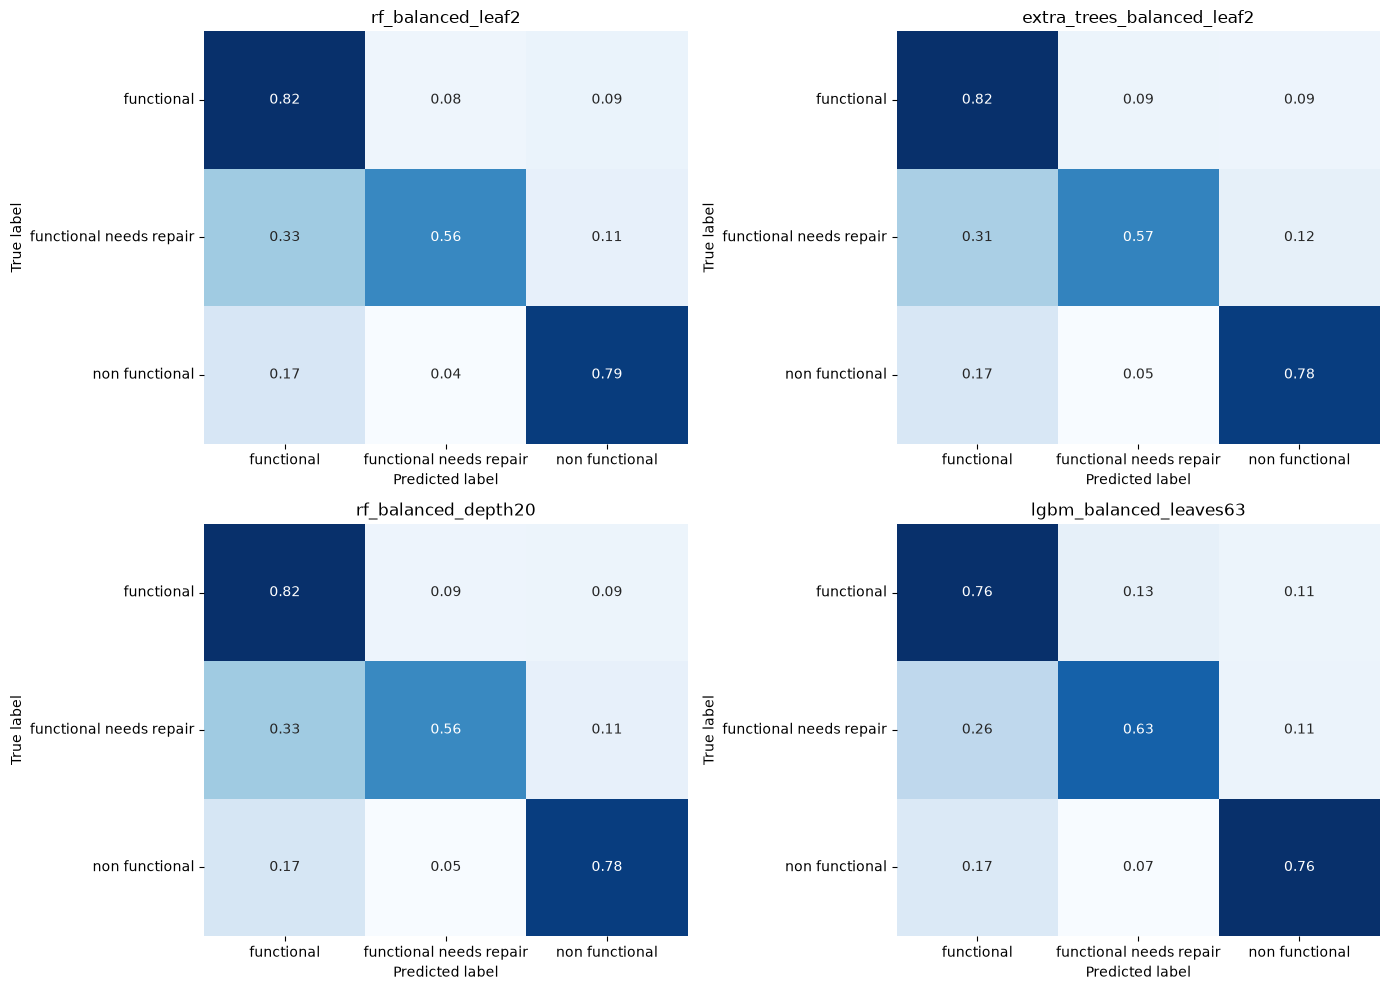

In [3]:
top_models = results.nsmallest(4, 'business_cost_mean')['model'].tolist()
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, model_name in zip(axes.flat, top_models):
    matrix = pd.DataFrame(confusion_matrices[model_name], index=labels, columns=labels)
    normalized = matrix.div(matrix.sum(axis=1), axis=0)
    sns.heatmap(normalized, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
plt.tight_layout()
plt.show()

## Decision framework

The business-cost column assigns five times more penalty to missing a pump that needs repair than to another classification error. This is a transparent starting assumption, not a measured operational contract. The portfolio demo exposes several trained models so the trade-off between overall performance and maintenance recall remains visible.